# 02 · BPDR methodology, Transformer and objectives

<a id="SETUP"></a>
<a id="10-SETUP"></a>
### `SETUP` · Setup: component environment and immutable evidence

In [1]:
# SETUP
from pathlib import Path
import sys
WORKSPACE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'source/bpdr_input').is_dir())
sys.path.insert(0, str(WORKSPACE / 'source'))
from bpdr_input.reporting.notebook_setup import prepare, load_catalogs, show
globals().update(prepare(WORKSPACE))
show(pd.DataFrame([{'check': 'Saved model and evidence identities', 'result': 'PASS',
                    'recorded_run': RUN.name}]))


,check,result,recorded_run
0,Saved model and evidence identities,PASS,b4c64c3b861a48c494c092458716b4fc


<a id="10-CONTEXT"></a>
### `CONTEXT` · Load local split catalogs and common helper names

In [2]:
# Code block: 10-CONTEXT
globals().update(load_catalogs(RUN, MANIFEST))
show(pd.DataFrame([
    dict(split=s, recordings=len(SOURCE_RECORDS[s]), singers=len(groups[s]),
         intervention_attempts=len(PAIRS[s])) for s in SPLITS
]))


,split,recordings,singers,intervention_attempts
0,train,16,8,64
1,calibration,4,2,16
2,pilot_evaluation,4,2,16


These are the **VocalSet recovery** catalogs: 24 recordings, 12 assigned singers and 96 intervention attempts, including exclusions. They are not the historical Transformer training set. Full source, split and feature details are shown in notebook 03.

## The four views and fixed time coordinates

| View | Physical audio | Boundary metadata | Desired correction |
|---|---|---|---|
| A | Original | Nominal | Preserve accepted material |
| B | Exactly the same as A | Split / merge / jitter | Similar to A |
| C | Physically rendered local detuning e | Nominal | Change from A by approximately −e |
| D | Exactly the same as C | Same boundary-corruption condition | Similar to C; change from B by approximately −e |

A/B and C/D measure boundary sensitivity. A/C and B/D measure compensating pitch response. One shared model processes all views. The output is a signed correction curve on a common frame timeline; changing the note count never changes those coordinates. A reliable voiced mask excludes silence, unreliable intervention regions and invalid pitch. Features must be re-extracted after rendering C; changing only a label while keeping A's spectrum would create an inconsistent experiment.

The plots below are **illustrations**, not learned predictions. A zero-output model passes boundary consistency perfectly but fails the required response to physical detuning. Correct C predictions with unstable D predictions also fail.

## Actual architecture and objectives

The saved architecture is a four-layer bidirectional Transformer: 71 inputs, hidden dimension 128, four attention heads, 512-dimensional feed-forward layers, dropout 0.1, positional encoding and padding masks. It returns an unbounded signed-cent value for each frame. It does not return a probability that a singer is right. The deterministic controller withholds over-limit predictions rather than clipping them into apparent validity.

Columns 0–63 are log-mel; column 64 is performed pitch, 65 confidence, 66 voicing, 67 adjacent pitch change, 68 log energy, 69 onset and 70 provisional boundary score. Runtime uses a documented fine-pitch adapter. Historical training adapters remain frozen; differences are limitations of checkpoint comparisons.

$$d_M(x,y)=\operatorname{mean}_{t\in M}|x_t-y_t|,$$
$$L_B=\tfrac12[d_M(r_A,r_B)+d_M(r_C,r_D)],$$
$$L_D=\tfrac12[d_M(r_C-r_A,-e)+d_M(r_D-r_B,-e)],$$
$$L=L_A+\lambda_B L_B+\lambda_D L_D+\lambda_S L_S.$$

In the base implementation, masked distances are calculated per example and averaged over examples with a nonempty mask; skipped examples are counted. L_A anchors unchanged A/B to zero and verified C/D to −e. L_S penalizes changes in the **correction curve** between adjacent voiced frames; it does not penalize the original expressive contour. The later squared-anchor variant uses cents² for L_A while the other terms remain absolute-cent distances. Loss magnitudes from different objectives are not directly comparable. The numerical illustration below uses the base objective. The [absolute-anchor implementation](../source/bpdr_input/modeling/losses.py) and [squared-anchor variant](../source/bpdr_input/experiments/learning/fine_pitch_mse_check.py) remain available in source. The saved checkpoint settings identify which objective was recorded.

Augmentation-only uses the same four-view training data and anchors/smoothness without the two response terms. Frame-only removes the boundary column (70 inputs) but remains a sequence Transformer of comparable capacity. The full BPDR arm adds the response objectives after warm-up. Matching sources, initialization, budgets and selection distinguishes an objective benefit from more data or computation. Independent held-out evaluation at comparable acceptance coverage is still required.

<a id="BPDR-EQUATIONS"></a>
### `BPDR-EQUATIONS` · Offline equation figure with plain-language units

In [3]:
# Code block: BPDR-EQUATIONS
formulas = ['$L_B=\\frac{1}{2}[d_M(r_A,r_B)+d_M(r_C,r_D)]$', '$L_D=\\frac{1}{2}[d_M(r_C-r_A,-e)+d_M(r_D-r_B,-e)]$', '$L=L_A+\\lambda_B L_B+\\lambda_D L_D+\\lambda_S L_S$']

<a id="BPDR-EQUATIONS-2"></a>
#### Visualize the result

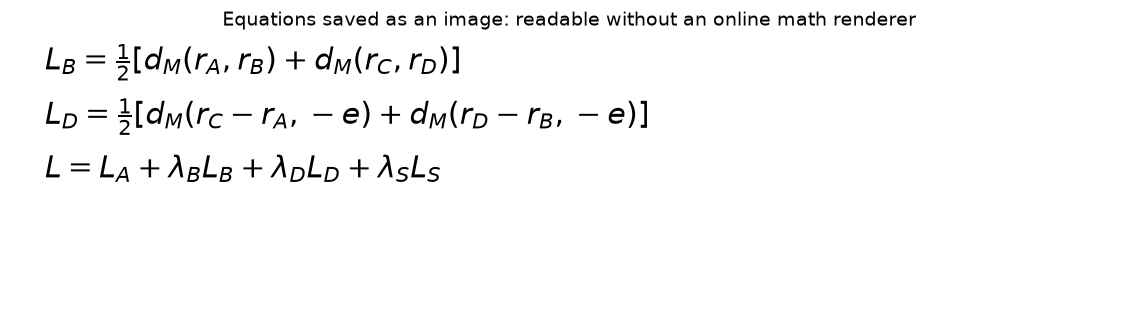

In [4]:
# Code block: BPDR-EQUATIONS-2
fig, ax = plt.subplots(figsize=(10, 3))
ax.set_axis_off()
for i, formula in enumerate(formulas):
    ax.text(0.03, 0.88 - i * 0.19, formula, fontsize=19, transform=ax.transAxes)
ax.set_title('Equations saved as an image: readable without an online math renderer')
plt.tight_layout()
plt.show()

<a id="BPDR-VIEWS"></a>
### `BPDR-VIEWS` · Four aligned views and split/merge/jitter demonstration

In [5]:
# Code block: BPDR-VIEWS
times = np.arange(0, 4, 0.02)
nominal = np.array([1.0, 2.0, 3.0])
boundaries = {'nominal': nominal, 'false split': np.array([1.0, 1.5, 2.0, 3.0]), 'false merge': np.array([1.0, 3.0]), 'jitter': nominal + 0.1}
illustrative_pitch = np.where(times < 1, 0, np.where(times < 2, 200, np.where(times < 3, 400, 200))).astype(float)
added = np.where((times >= 2.2) & (times < 2.8), 20.0, 0.0)

<a id="BPDR-VIEWS-2"></a>
#### Visualize the result

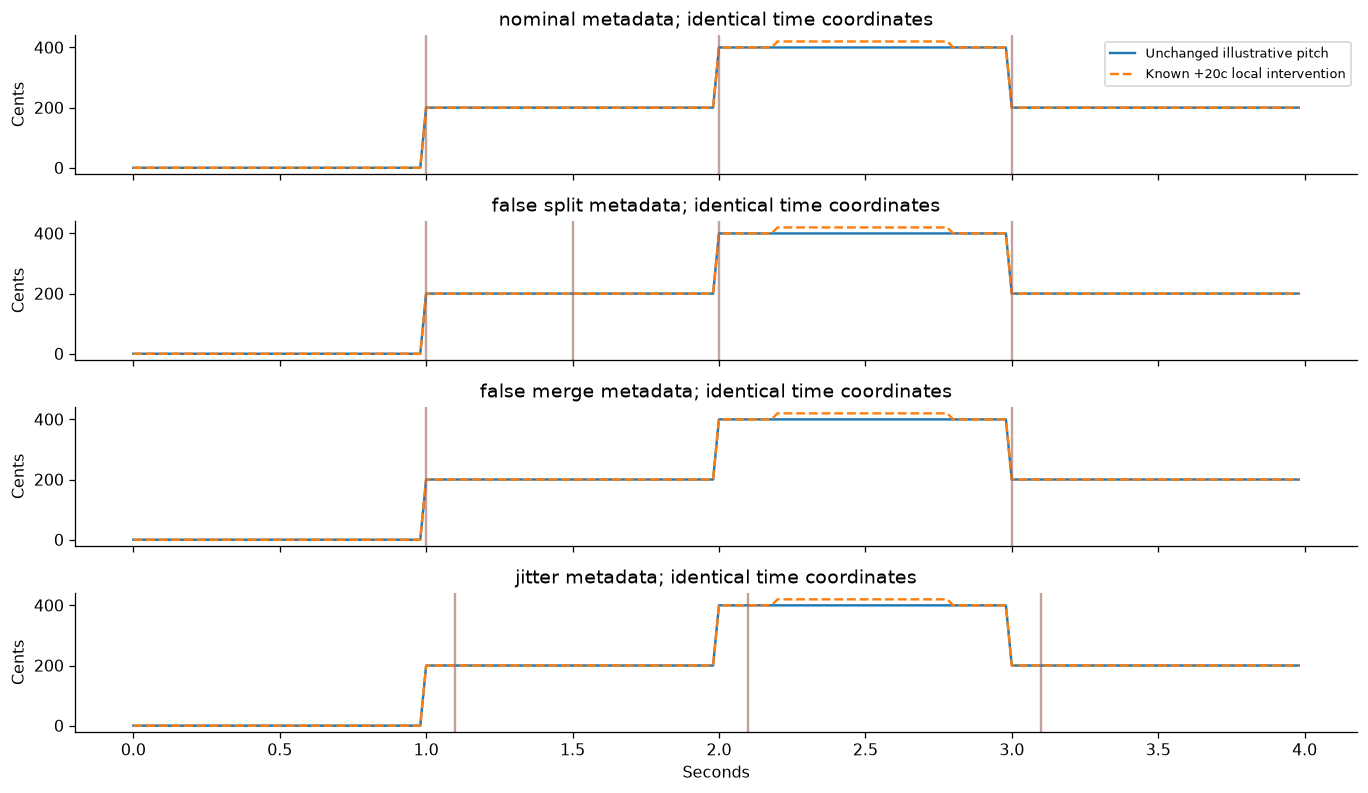

In [6]:
# Code block: BPDR-VIEWS-2
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for ax, (name, edges) in zip(axes, boundaries.items()):
    ax.plot(times, illustrative_pitch, label='Unchanged illustrative pitch')
    ax.plot(times, illustrative_pitch + added, linestyle='--', label='Known +20c local intervention')
    for edge in edges:
        ax.axvline(edge, color=COLORS['input'], alpha=0.6)
    ax.set(ylabel='Cents', title=name + ' metadata; identical time coordinates')
axes[0].legend(fontsize=8)
axes[-1].set_xlabel('Seconds')
plt.tight_layout()
plt.show()

<a id="BPDR-VIEWS-3"></a>
#### Inspect the result

In [7]:
# Code block: BPDR-VIEWS-3
table = [dict(view=v, waveform='original' if v in 'AB' else 'original + local detuning', boundaries='nominal' if v in 'AC' else 'corrupted') for v in 'ABCD']
show(pd.DataFrame(table))

,view,waveform,boundaries
0,A,original,nominal
1,B,original,corrupted
2,C,original + local detuning,nominal
3,D,original + local detuning,corrupted


 Each row changes only the vertical boundary lines. Solid and dashed contours are identical across rows, except that the dashed contour includes the same +20-cent region in every row. The rows are boundary scenarios, not A/B/C/D predictions.

<a id="BPDR-LOSSES"></a>
### `BPDR-LOSSES` · Compare three correction behaviors

In [8]:
# BPDR-LOSSES
from bpdr_input.modeling.losses import objective, LossWeights, boundary_invariance, counter_detuning, masked_mean_abs, smoothness
e = torch.tensor([[0.0, 0.0, 20.0, 0.0]])
mask = torch.ones_like(e, dtype=torch.bool)
good = {v: torch.tensor([[0.0, 0.0, -20.0 if v in 'CD' else 0.0, 0.0]]) for v in 'ABCD'}
zero = {v: torch.zeros_like(e) for v in 'ABCD'}
wrong = {v: -good[v] for v in 'ABCD'}
batch = dict(mask=mask, detuning=e, voiced={v: mask for v in 'AC'})
examples = []
for name, predictions in [('Correct compensation', good), ('Always zero', zero), ('Wrong correction sign', wrong)]:
    total, parts, skipped = objective(predictions, batch, 'bpdr', LossWeights())
    examples.append(dict(example=name, **{k: float(v) for k, v in parts.items()}, total=float(total), skipped=str(skipped)))
show(pd.DataFrame(examples).drop(columns='skipped').round(4))

,example,anchor,smoothness,boundary,detuning,total
0,Correct compensation,0.0000,6.6667,0.0000,0.0000,0.6667
1,Always zero,2.5000,0.0000,0.0000,5.0000,7.5000
2,Wrong correction sign,5.0000,6.6667,0.0000,10.0000,15.6667


Correct compensation has zero anchor, boundary and detuning error, but a small smoothness penalty. Always-zero predictions pass boundary consistency and fail response. Values average four toy frames, only one shifted; they are not dataset metrics.

<a id="TRANSFORMER-MODEL"></a>
### `TRANSFORMER-MODEL` · Load actual Transformer, shape/parameter checks and stored protocol

In [9]:
#TRANSFORMER-MODEL
from bpdr_input.reporting.bpdr_showcase import load_model as load_transformer
from bpdr_input.modeling.model import CorrectionEncoder, ModelConfig
transformer_card = read_json(WORKSPACE / 'selected_model/model.json')
transformer_path = WORKSPACE / 'selected_model' / transformer_card['checkpoint']
encoder, normalizer, width = load_transformer(transformer_path)
show(pd.DataFrame([encoder.describe()]))

,features,hidden,layers,heads,feed_forward,dropout,parameters
0,71,128,4,4,512,0.1000,802433


<a id="TRANSFORMER-MODEL-2"></a>
#### Inspect the result

In [10]:
#  TRANSFORMER-MODEL-2
dummy = torch.zeros((1, 20, width))
with torch.inference_mode():
    prediction = encoder(dummy)
assert prediction.shape == (1, 20) and torch.isfinite(prediction).all()
saved = torch.load(transformer_path, map_location='cpu', weights_only=False)
print('Stored checkpoint protocol:', saved['protocol'])
historical_index = read_json(WORKSPACE / 'notebooks/evidence_index.json')
adaptation = COMPONENT / HISTORY_PATHS['adaptation_evidence']
adaptation_declaration = read_json(adaptation.parent / 'declaration.json')
show(pd.DataFrame([{'setting': k, 'recorded_value': str(v)} for k, v in adaptation_declaration.items() if k not in ('frozen', 'version')]))

Stored checkpoint protocol: {'fit': {'seed': 339}, 'model': {'hidden': 128, 'layers': 4, 'heads': 4, 'feed_forward': 512, 'dropout': 0.1}}


,setting,recorded_value
0,declared_utc,2026-10-17T14:30:13.935270+00:00
1,seed,339
2,source_sha256,9e612c77b1a8b5084077604d60b8e5a1dac4832cf56badf84a21371a5cef1026
3,updates_per_condition,300
4,effective_batch,8
5,learning_rate,0.0001
6,optimizer,"AdamW, weight_decay .01, gradient clip 1"
7,initialization,"Frozen synthetic seed 339, same corresponding condition; original checkpoints never overwritten"
8,real_records,995
9,synthetic_records,384


The architecture table describes the actual saved Transformer. A (1, 20) dummy output verifies shape and finite values only. Recorded optimizer updates and effective batch describe training; no fitting occurs here.

<a id="BPDR-BASELINES"></a>
### `BPDR-BASELINES` · Capacity and source-code verification of matched conditions

In [11]:
#  BPDR-BASELINES
from bpdr_input.modeling.model import CorrectionEncoder, ModelConfig
capacities = []
for condition, width in [('augmentation_only', 71), ('frame_only', 70), ('bpdr', 71)]:
    encoder = CorrectionEncoder(ModelConfig(features=width))
    capacities.append(dict(condition=condition, features=width, parameters=encoder.parameter_count(), objective='anchors + smoothness + response terms' if condition == 'bpdr' else 'anchors + smoothness'))
show(pd.DataFrame(capacities))

,condition,features,parameters,objective
0,augmentation_only,71,802433,anchors + smoothness
1,frame_only,70,802305,anchors + smoothness
2,bpdr,71,802433,anchors + smoothness + response terms


 The first two conditions use anchors and smoothness; BPDR adds paired response losses. Frame-only excludes boundary metadata but still processes a sequence. Loading architectures does not establish superiority.